# Classification of hand-written digits with PyTorch

We import the necessary libraries

In [ ]:
import torch
from torchvision import datasets, transforms

`torchvision.transform`

*   is a library of transformations we can perform on images
*   they  accept PIL Image, Tensor Image or batch of Tensor Images as input.
*   below we define transformations to convert images to tensors


In [ ]:
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))])

* `Compose` applies the transformations one after the other
* `ToTensor()` gives a tensor from an image
* `Normalize` the tensors

---

In [ ]:
trainset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)

`torchvision.datasets` provides many dataset, here we download MNIST, a collection of images with hand-written digits 0, 1, 2, ..., 9.

`trainset` can be thought as the list of all the images of the dataset MNIST one after the other and with their label (the digit in it).

Notice that we can directly apply the trasformations and obtain the set of tensors as trainset.

We can access both the data and the targets by the attributes `trainset.data` and `trainset.target`. Let us check their sizes:

In [ ]:
print(f"Data    : {trainset.data.shape}")
print(f"Targets : {trainset.targets.shape}")

Data    : torch.Size([60000, 28, 28])
Targets : torch.Size([60000])


So there are 60 000 images in the data set, each one represented by a 2d tensor (a matrix) of shape 28x28. The `targets` are the labels of each image and they tell us the digits written in the image.

In [ ]:
print(trainset.targets)

tensor([5, 0, 4,  ..., 5, 6, 8])


The first image is a 5, the second is a 0 and so forth.

If we want to visualise the images it is useful to write a function that display it. We can do it with matplotlib

In [ ]:
import matplotlib.pyplot as plt

The following function takes an index 0 <= n < 60 000 and prints the label and the picture.

In [ ]:
def show_train_image(n):
  if n < 0 or n >= 60000:
    print(f"Error: index {n} out of bounds.")
    return
  else:
    img, num = trainset[n]
    print(f"Label : {num}")
    plt.figure(figsize = (20,2))
    plt.imshow(img[0], cmap='gray')
    return

Here there are some exemples

Label : 5
Label : 0
Label : 5
Label : 8


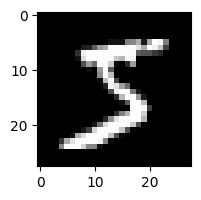

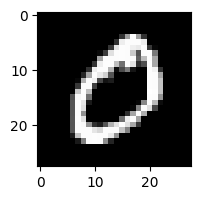

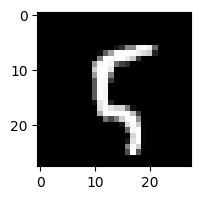

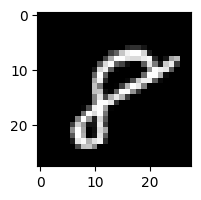

In [ ]:
show_train_image(0)
show_train_image(1)
show_train_image(100)
show_train_image(59999)

## The neural network

We now use the library `torch.nn` to create the MLP.

In [ ]:
import torch.nn as nn

We use the class Module, which need to implement the __init__function and the forward() method.

In [ ]:
class NN_MNIST(nn.Module):
    def __init__(self):
        super(NN_MNIST, self).__init__()
        # 1. Flatten 2D images (28x28) into 1D vectors (784)
        self.flatten = nn.Flatten()

        # 2. Define the hidden layers
        self.fc1 = nn.Linear(28 * 28, 128)  # Input layer to Hidden layer (128 neurons)
        self.fc2 = nn.Linear(128, 10)       # Hidden layer to Output layer (10 digit classes)

    def forward(self, x):
        # x starts as shape: [64, 1, 28, 28]
        x = self.flatten(x)                 # Shape becomes: [64, 784]
        x = nn.functional.relu(self.fc1(x)) # Pass through hidden layer with ReLU activation
        x = self.fc2(x)                     # Output raw logits for the 10 classes
        return x

* `self.flattent` is a function that flatten a tensor (28x28) into a 1D vector (784). This function is used in the forward pass to reshape the input.
* The input layer has 784 neurons, the hidden layer has 128 neurons, the output layer has 10 neurons
* `nn.Linear` Applies an affine linear transformation to the incoming data:
y=xAT+b.
* `forward()` computes the final output: it flattens the image, it computes the activation in the hiden layer, it computes the output.
* The output is a tensor with the logits for each 10 classes, the higher logit tell what is the most likely digit in the image.
* The forward setp is computed on a batch of 64 immages, so the output will be a tensor of size 64x10.

Remember that weight and biases are thought to be on the connections between neurons.

In [ ]:
model = NN_MNIST()
print(model)

We can try to do a forward step and visualize the output. First we build a batch of data with `DataLoader`.

In [ ]:
trainloader = torch.utils.data.DataLoader(trainset, batch_size=64, shuffle=True)

**What is a `Dataloader` and what is the difference with a `Dataset`?**

When we did `trainset = dataset.MNIST`, we created an object that handles individual items, so we index it directly and calling `trainset[0]`, `trainset[1]`, `trainset[2]`, ..., it returns the single image tensor and the label integer corresponding to 0, 1, 2, ...

A DataLoader wraps around the dataset we specified in its argument and organizes the individual items into batches of the size we specified, in our case 64. So, whereas a dataset can be thought as the list of our training data (individually), the `DataLoader` can be thought as the list of batches of a specific size with items in the given dataset.

An item of the dataset belongs to one unique batch of the `DataLoader`.

**Remark:** It is not convenient to transform a Dataloader into a list to visualize the batches because it takes a lot of memory. A better way is to build an iterator and access it elements.

In [ ]:
dataiter = iter(trainloader)
images, labels = next(dataiter)

print("First batch shape:", images.shape)
print("type(images) = ", type(images))
print("type(labels) = ", type(labels))

`iter` and `next` are bult-in function in python, see [documentiation here](https://docs.python.org/3/builtins/functions.html#iter). The function `iter` builds an iterator object using its arguent, `next` is then used to return the first element, then the second and all the following it applied again.

Now we test if we can apply the forward pass on this batch.

In [ ]:
outputs = model(images)

print("Model output shape (logits):", outputs.shape)
print("type(outputs) = ", type(outputs))
print(outputs[0])

We are ready to train our neural network:

* Our training data (60 000 images with labels) are organized into batches in `trainloader`.
* The neural network is initialised in `model`.
* Batches are correctly processed by the forward pass.

## Training the neural network

Some reminder on the structure:

* Our neural network has 28x28 = **784** neuron in the first (input) layer, **128** in the second (hidden) layer, and **10** in the last (output) layer.
* The first-to-second Linear application in `model` has initialised weights an biases: `model.fc1.weight` and `model.fc1.bias`. The second-to-last layer is analog.

In [ ]:
print("w1 = ", model.fc1.weight.shape)
print("b1 = ", model.fc1.bias.shape)
print("\n")
print("w2 = ", model.fc2.weight.shape)
print("b2 = ", model.fc2.bias.shape)


By default, the nn.Linear function initializes weight and biases tensor with gradients. This is important in the training because gradients are updated at each back propagation and used to correct the parameters.

In [ ]:
print(model.fc1.weight.requires_grad)
print(model.fc1.bias.requires_grad)
print(model.fc2.weight.requires_grad)
print(model.fc2.bias.requires_grad)

Once the gradients have been updated, we need to use it to correct the weights. We can do it by the gradient descent or by the Adam optimizer.

In [ ]:
import torch.optim as optim

optimizer = optim.Adam(model.parameters(), lr=0.001)

Then we defined the loss function, that is a measure of how differen the predictions are from the correct labels. Here we choose the **cross entropy**.

In [ ]:
# Cross entropy: sum(y log(y))
criterion = nn.CrossEntropyLoss()

To training the neural network we visit the trainloader and we tune the parameters of the model. We choose how many times we iterate the trainloader. Each iteration is called epoch and we decide to set the number of them to 5.

In [ ]:
epochs = 5

Now we start the training loops. The first for loop correspond to the epoches. At each epoch we iterate over the trainloader and for each batch we do the following:

1.   We set all gradients to 0.
2.   Compute the forward pass on the batch.
3.   Compute the loss function (how far we are from the target).
4.   Compute the gradients by back propagation.
5.   Update the weights and biases with the optimizer.

The line `model.train()` set the model in training mode.



In [ ]:
for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    correct_predictions = 0
    total_samples = 0

    for i, (images, labels) in enumerate(trainloader):
        # 1.
        optimizer.zero_grad()

        # 2.
        outputs = model(images)

        # 3.
        loss = criterion(outputs, labels)

        # 4.
        loss.backward()

        # 5.
        optimizer.step()

        # Monitoring
        running_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)
        correct_predictions += (predicted == labels).sum().item()
        total_samples += labels.size(0)

    # Calcola loss e accuratezza media dell'epoca
    epoch_loss = running_loss / total_samples
    epoch_acc = correct_predictions / total_samples

    print(f"Epoch [{epoch+1}/{epochs}] - Loss: {epoch_loss:.4f} - Accuracy: {epoch_acc * 100:.2f}%")

print("Training completed!")

`running_loss` is the current value of the loss and it is minimized along the training, `correct_predictions` counts how many images are correctly labeled. At the end of each epoch, the loss is averaged over all the samples and the accuracy is the ratio between correct predictions and total samples.

`torch.max(input, dim)` computes the maximum in input along dimension `dim`, it returnes the tensor of such maximum and the tensor of the indices where it occured. Thus, predicted now stores the tensor of the indices which, in our case, coincide with the labels.

## Testing the model

We now build the set of testing data, we can do it with the flag `train=False` in the dataset call.

In [ ]:
testset = datasets.MNIST(root='./data', train=False, download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=64, shuffle=False)

Our test set is composed by 10 000 images with their label:

In [ ]:
print(f"Data    : {testset.data.shape}")
print(f"Targets : {testset.targets.shape}")

We set the model in evaluation mode and prepare the testing parameters.



In [ ]:
model.eval()
test_correct = 0
test_total = 0

We disabled gradient calculation to save memory and speed up testing.

In [ ]:
with torch.no_grad():
    for images, labels in testloader:
        outputs = model(images)
        _, predicted = torch.max(outputs, 1)
        test_total += labels.size(0)
        test_correct += (predicted == labels).sum().item()

test_accuracy = test_correct / test_total
print(f"Accuracy on Test Set: {test_accuracy * 100:.2f}%")

The test is successful and the accuracy is very good. We can visualize it by a similar function to display the image, the label and the prediction.

In [ ]:
def show_test_image(n):
  if n < 0 or n >= 10000:
    print(f"Error: index {n} out of bounds.")
    return
  else:
    img, num = testset[n]
    output = model(img)
    _, predicted = torch.max(output, 1)
    print(f"Label      : {num}")
    print(f"Prediction : {predicted.item()}")
    plt.figure(figsize = (20,2))
    plt.imshow(img[0], cmap='gray')
    return

In [ ]:
show_test_image(0)

In [ ]:
show_test_image(10)

In [ ]:
show_test_image(1000)